# Statistical GAMs in depth

**Objective:** choose a response family, select basis capacity using validation
data, model group shifts and exposure offsets, and distinguish uncertainty
about a fitted mean from conditional response spread. Prerequisite:
[fit and diagnose a GAM](../tutorials/first_gam.rst). Allow about a minute on
CPU; the execution note records tested versions and actual runtime.

## Penalized smooths and a known data-generating process

A smooth expands in basis functions $f(x)=\sum_r b_r(x)\beta_r$.
Penalized likelihood minimizes $-\ell(\beta;y)+\frac12\lambda\beta^T S\beta$.
The basis dimension limits available capacity; the penalty controls how much
is used. The simulation below combines a nonlinear mean, a group shift, and
changing noise. A second outcome is a count whose mean scales with exposure.

**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source base commit `4cffdeb` (working checkout); elapsed 3.5 seconds on this CPU. Runtime varies by hardware.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_poisson_deviance
from nampy.models import GAMRegressor, GAMLSS

rng = np.random.default_rng(21)
x = rng.uniform(0, 1, 800)
group = pd.Categorical(rng.choice(["a", "b"], size=len(x)))
shift = 0.4 * (group == "b")
scale = 0.12 + 0.2 * x
exposure = rng.uniform(0.5, 2.5, len(x))
data = pd.DataFrame({"x": x, "group": group, "log_exposure": np.log(exposure)})
data["y"] = 1 + np.sin(2*np.pi*x) + shift + scale*rng.normal(size=len(x))
data["count"] = rng.poisson(exposure * np.exp(0.1 + 0.6*np.sin(2*np.pi*x) + shift))
fit_data, test = train_test_split(data, test_size=0.2, random_state=21)
train, validation = train_test_split(fit_data, test_size=0.25, random_state=22)


## Select capacity without using the test set

Both candidates use REML to select smoothness. Validation compares their
basis dimensions; it does not replace smoothness selection. The untouched
test set is evaluated only after selecting a candidate. Categorical group
terms represent baseline shifts, not separate nonlinear curves.

In [2]:
candidates = {}
validation_scores = {}
for k in [8, 12]:
    candidate = GAMRegressor(formula=f"y ~ s(x, bs='cr', k={k}) + group").fit(train)
    candidates[k] = candidate
    validation_scores[k] = r2_score(validation.y, candidate.predict(validation))
best_k = max(validation_scores, key=validation_scores.get)
model = candidates[best_k]
print("Selected basis dimension:", best_k)
print("Untouched test R2:", r2_score(test.y, model.predict(test)))
model.summary()


Selected basis dimension: 8
Untouched test R2: 0.9176610338800154

Family: gaussian
Link function: identity

Formula:
y ~ s(x, bs='cr', k=8) + group

Parametric coefficients:
                 Estimate   Std. Error      t value     Pr(>|t|)    
(Intercept)        1.0318     0.015889        64.94       <2e-16 ***
group[b]          0.36265     0.022037       16.456       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Approximate significance of smooth terms:
                      edf       Ref.df            F      p-value    
s(x)               6.7263       6.9715       619.81       <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

R-sq.(adj) = 0.906   Deviance explained = 90.8%
-REML = 17.814  Scale est. = 0.057941  n = 480


GAMSummary(family_name='gaussian', link_name='identity', formula="y ~ s(x, bs='cr', k=8) + group", p_coeff=array([1.0317985 , 0.36265058]), se=array([0.01588855, 0.02203703, 0.03940882, 0.0313073 , 0.0350306 ,
       0.03363011, 0.03242407, 0.03577265, 0.05641582]), p_t=array([64.93976105, 16.45642009]), p_pv=array([3.01964320e-237, 2.08479479e-048]), p_table=             Estimate  Std. Error    t value       Pr(>|t|)
(Intercept)  1.031799    0.015889  64.939761  3.019643e-237
group[b]     0.362651    0.022037  16.456420   2.084795e-48, pterms_table=   label   df   wald_stat       p_value test covariance  dispersion
0  group  1.0  270.813762  2.084795e-48    F      bayes    0.057941, s_table=  label       edf    ref_df   wald_stat  p_value test term_type basis_name  \
0  s(x)  6.726302  6.971545  619.809863      0.0    F    smooth         cr   

  covariance  dispersion  
0      bayes    0.057941  , residual_df=471.2736980047323, m=1, scale=0.05794090801369287, dispersion=0.05794090801

## Read effects and pointwise uncertainty

The smooth curve is a centered link-scale contribution. Its band describes
uncertainty in the estimated function conditional on the fitted model and
covariance convention. It does not describe the scatter of future outcomes.
A larger basis is not automatically a better fit; inspect residuals and
basis diagnostics in the [full diagnostic tutorial](../tutorials/first_gam.rst).

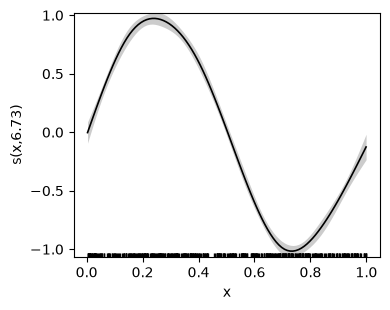

,term,term_type,output,importance
0,"s(x, bs='cr', k=8)",main,0,0.639093
1,group[b],main,0,0.215324


In [3]:
figures = model.plot(pages=1, scheme=1, scale=0)
plt.show()
plt.close("all")
parts = model.predict_components(test)
parts.validate_additive_reconstruction()
model.term_importance(test)


## Model exposure with a known offset

For counts with exposure $e$, use
$\log\mu(x,e)=f(x)+u_{\mathrm{group}}+\log e$.
The offset has fixed coefficient one. Doubling exposure therefore doubles
expected counts at the same feature values. It does not duplicate observations
or change their sample weights. A Poisson family links variance to the mean;
extra dispersion would motivate another family or model.

Offsets must also be present for prediction rows. Compare held-out count
predictions using a count-appropriate loss rather than plotting their score
against Gaussian R².

Test mean Poisson deviance: 1.170280859893275


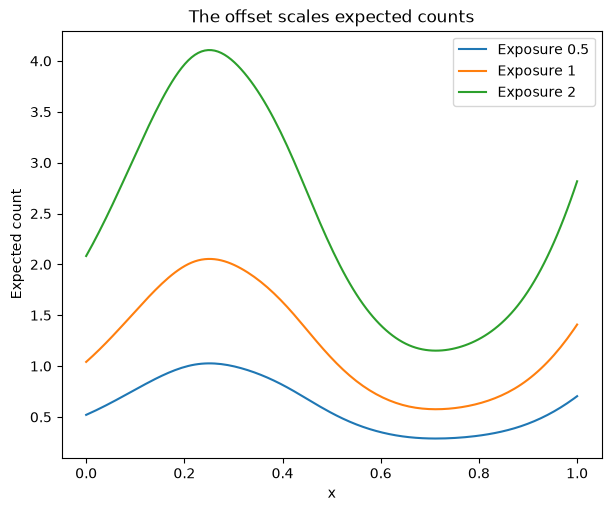

In [4]:
count_model = GAMRegressor(
    formula="count ~ s(x, bs='cr', k=10) + group + offset(log_exposure)",
    family="poisson",
).fit(train)
count_prediction = count_model.predict(test)
assert np.all(count_prediction > 0)
print("Test mean Poisson deviance:", mean_poisson_deviance(test["count"], count_prediction))

figure, axis = plt.subplots(figsize=(6, 5), constrained_layout=True)
for exposure in [0.5, 1.0, 2.0]:
    grid = pd.DataFrame({"x": np.linspace(0, 1, 150),
                         "group": pd.Categorical(["a"]*150, categories=data.group.cat.categories),
                         "log_exposure": np.log(exposure)})
    axis.plot(grid.x, count_model.predict(grid), label=f"Exposure {exposure:g}")
axis.set(xlabel="x", ylabel="Expected count", title="The offset scales expected counts")
axis.legend()
plt.show()
plt.close(figure)


## Fit changing response spread jointly with location

For a normal location-scale model, each parameter has its own additive
predictor. A response contributes $\log\sigma+(y-\mu)^2/(2\sigma^2)$ plus a
constant to negative log likelihood. Location and scale are estimated together,
not by fitting a second model to squared residuals. Natural parameter transforms
enforce $\sigma>0$. The statistical backend's raw scale predictor is
precision-related, so it should not be equated with a neural family's raw
scale output.

Here we plot fitted **natural** location and standard deviation. The scale
curve describes response variability, whereas the earlier smooth band
quantified uncertainty about a fitted effect.

Test negative log likelihood: {'Negative Log-Likelihood': -0.12923635365911257}


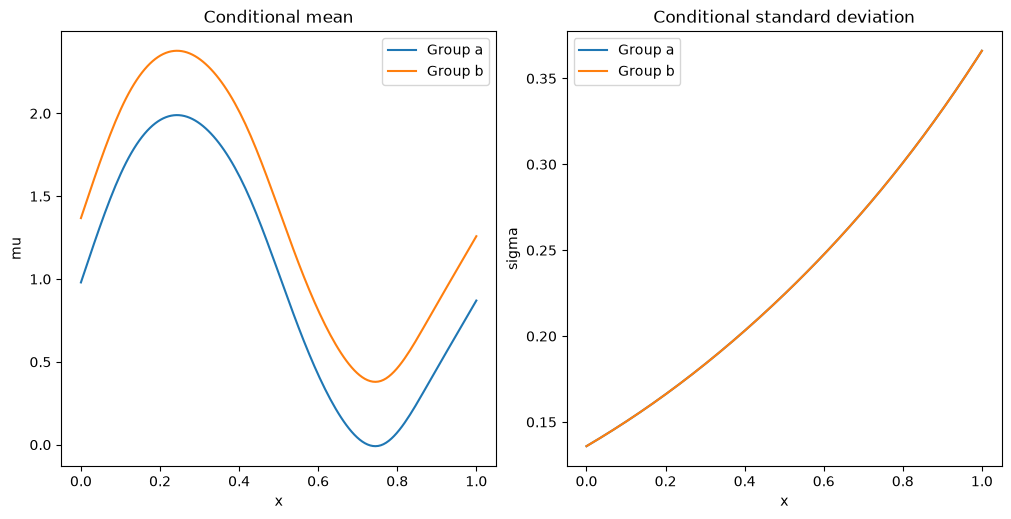

In [5]:
distributional = GAMLSS(family="normal", formula={
    "mu": "y ~ s(x, bs='cr', k=10) + group",
    "sigma": "~ s(x, bs='cr', k=8)",
}).fit(train)
parameters = distributional.predict(test)
assert parameters.shape == (len(test), 2)
assert np.all(parameters[:, 1] > 0)
components = distributional.predict_components(test)
components.validate_additive_reconstruction()
assert all(metadata.kind == "main" for metadata in components.term_metadata.values())
print("Test negative log likelihood:", distributional.evaluate(test, test.y.to_numpy()))

figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for group in data.group.cat.categories:
    grid = pd.DataFrame({"x": np.linspace(0, 1, 150),
                         "group": pd.Categorical([group]*150, categories=data.group.cat.categories)})
    mu, sigma = distributional.predict(grid).T
    axes[0].plot(grid.x, mu, label=f"Group {group}")
    axes[1].plot(grid.x, sigma, label=f"Group {group}")
axes[0].set(title="Conditional mean", xlabel="x", ylabel="mu")
axes[1].set(title="Conditional standard deviation", xlabel="x", ylabel="sigma")
for axis in axes:
    axis.set_box_aspect(1)
    axis.legend()
plt.show()
plt.close(figure)


## Go further

[The visual formula guide](../user_guide/formula_visual_reference.rst) explains
group-specific smooths, random effects, cyclic terms, and tensor interactions.
[The statistical validation report](../development/notebooks/02_statistical_gams.ipynb)
executes the broader basis/family/optimizer interfaces. Exact signatures and
supported combinations belong to the [API reference](../api/gam.rst) and
[runtime-checked optimizer matrix](../development/optimizer_matrix.rst).
